# Quantity Analysis - Time Series

## Objective
Analyze and forecast **quantity trends** over time using time series analysis techniques.

## Dataset Overview
The dataset contains timestamped records of quantities sold or produced.

## Workflow
1. Load the data
2. Explore time-based patterns
3. Resample and smooth
4. Train a forecasting model
5. Visualize predictions

In [15]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error
import warnings
warnings.filterwarnings("ignore")


In [8]:
# Load data from Excel file
df = pd.read_excel('Raw Data_Predictive Analysis.xlsx')

# Disaplay the first few rows of the dataframe
print(df.head())
print(df.info())

   OrderDate  ParentProductIdNew ParentProductNew ProductCategoryNew  \
0 2019-01-01                  11       Product 11         Category 1   
1 2019-01-01                 114      Product 114         Category 8   
2 2019-01-01                  98       Product 98         Category 8   
3 2019-01-01                  97       Product 97         Category 8   
4 2019-01-01                   8        Product 8         Category 1   

  ArtistNameNew  total_qty_sales  Selling Price  productListViews  \
0         TSSOS                3          399.0               NaN   
1          TSSA               10          549.0               NaN   
2         TSSHT                8          499.0               NaN   
3          TSSF                6          549.0               NaN   
4         TSSML                6          399.0               NaN   

   productListClicks  
0                NaN  
1                NaN  
2                NaN  
3                NaN  
4                NaN  
<class 'pandas

Excellent! It looks like the data has loaded successfully this time. You can see the first few rows of your DataFrame, and the df.info() output provides a summary of your data:
 * You have 40,563 entries (rows).
 * There are 9 columns in your DataFrame.
 * You can see the data type of each column.
 * Crucially, you can observe the "Non-Null Count" for each column.
As we noted earlier, the productListViews and productlistClicks columns have significantly fewer non-null values (25,591) compared to the total number of entries (40,563). This confirms the presence of missing values (represented as NaN).

#Imputing values if needed

In [10]:
#Impute missing values in 'productlistviews' and 'productlistclicks' with their medians
median_views = df['productListViews'].median()
median_clicks = df['productListClicks'].median()

df['productListViews'].fillna(median_views, inplace=True)
df['productListClicks'].fillna(median_clicks,inplace=True)

#verify that there is no more missing values in these columns
print("Missing values after imputation:")
print(df[['productListViews', 'productListClicks']].isnull().sum())

#display info again to see the updated non-null counts 
print("\nDataFrame Info after imputation:")
print(df.info())

Missing values after imputation:
productListViews     0
productListClicks    0
dtype: int64

DataFrame Info after imputation:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40563 entries, 0 to 40562
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   OrderDate           40563 non-null  datetime64[ns]
 1   ParentProductIdNew  40563 non-null  int64         
 2   ParentProductNew    40563 non-null  object        
 3   ProductCategoryNew  40563 non-null  object        
 4   ArtistNameNew       40563 non-null  object        
 5   total_qty_sales     40563 non-null  int64         
 6   Selling Price       40563 non-null  float64       
 7   productListViews    40563 non-null  float64       
 8   productListClicks   40563 non-null  float64       
dtypes: datetime64[ns](1), float64(3), int64(2), object(3)
memory usage: 2.8+ MB
None


 * df['productListViews'].median() calculates the median of the productListViews column.
 * df['productListViews'].fillna(median_views, inplace=True) fills all NaN values in the productListViews column with the calculated median_views. inplace=True modifies the DataFrame directly. We do the same for productlistClicks.
 * The isnull().sum() check will confirm that the missing value counts for these columns are now 0.

## Exploratory Data Analysis

In [18]:
# Convert 'OrderDate' to datetime objects
df['OrderDate'] = pd.to_datetime(df['OrderDate'])

# Set 'OrderDate' as the DataFrame index
df.set_index('OrderDate', inplace=True)

# Sort the index to ensure chronological order
df.sort_index(inplace=True)

# Display the first few rows with the new index
print(df.head())

# Check the DataFrame info again to confirm the index type
print(df.info())


KeyError: 'OrderDate'

In [19]:
# Ensure the index is a DatetimeIndex and sorted
if not isinstance(df.index, pd.DatetimeIndex):
	df.index = pd.to_datetime(df.index)

df.sort_index(inplace=True)

# Display the first few rows with the index
print(df.head())

# Check the DataFrame info again to confirm the index type
print(df.info())

            ParentProductIdNew ParentProductNew ProductCategoryNew  \
OrderDate                                                            
2019-01-01                  11       Product 11         Category 1   
2019-01-01                 114      Product 114         Category 8   
2019-01-01                  98       Product 98         Category 8   
2019-01-01                  97       Product 97         Category 8   
2019-01-01                   8        Product 8         Category 1   

           ArtistNameNew  total_qty_sales  Selling Price  productListViews  \
OrderDate                                                                    
2019-01-01         TSSOS                3          399.0            5026.0   
2019-01-01          TSSA               10          549.0            5026.0   
2019-01-01         TSSHT                8          499.0            5026.0   
2019-01-01          TSSF                6          549.0            5026.0   
2019-01-01         TSSML                6

 * The df.head() output now shows OrderDate as the index, which is what we wanted.
 * The df.info() output confirms that the OrderDate is now the DatetimeIndex. This means pandas recognizes it as a time series, which is crucial for the upcoming analysis.
 * All other columns still show 40563 Non-Null values, confirming that your imputation of missing values was successful.
You've completed the initial data preparation steps for time series analysis.

Daily Total Sales:
OrderDate
2019-01-01    293
2019-01-02    351
2019-01-03    319
2019-01-04    341
2019-01-05    308
Freq: D, Name: total_qty_sales, dtype: int64

 Missing values in daily_sales after re-sampling:
0


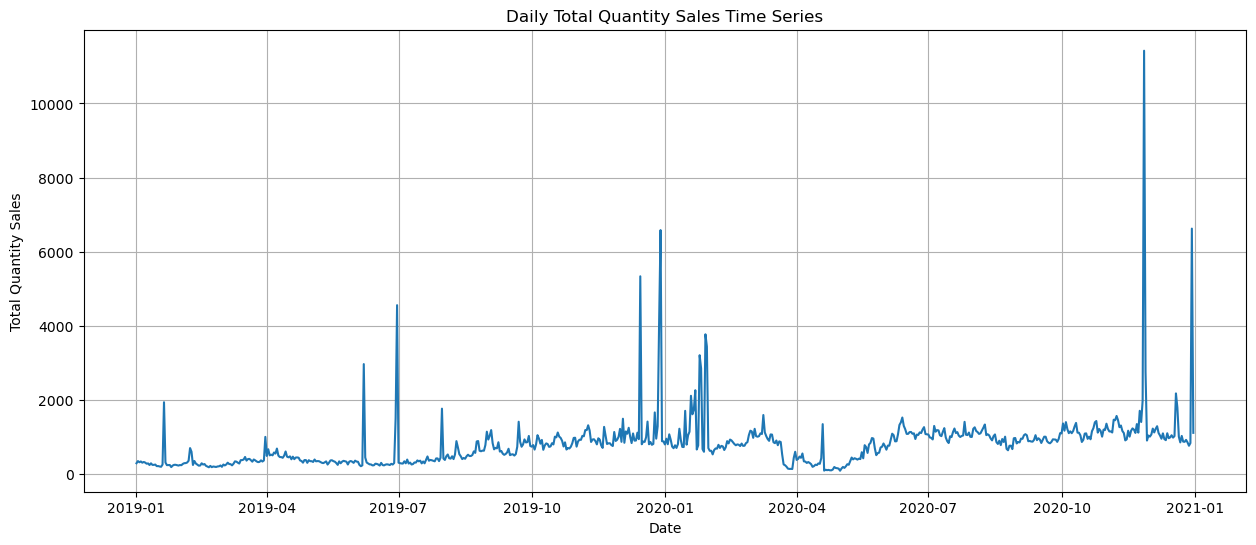

In [20]:
#Before plotting, we should consider resampling the data we'll start with total_qty_sales as your primary time series for forecasting.current data has a very high frequency (likely daily, with multiple entries per day). For many time series models,
#For many time series models, especially those looking for trends and seasonality, it's often better to aggregate the data to a consistent frequency, such as daily, weekly, or monthly totals.
#This aggregates all sales on a given day into a single value for that day.

# select the 'total_qty_sales' column
sales_data = df['total_qty_sales']

#re-sample the data to daily frequency, summing the sales for each day
#D stands for daily_frequency
daily_sales = sales_data.resample('D').sum()

#Display the first few rows of the resampled data
print("Daily Total Sales:")
print(daily_sales.head())

#check for any missing dates in the re-sampled data(e.g., days with no sales)
#If there are, they will be NaN. you might want to fill these with 0 if appropriate.
print("\n Missing values in daily_sales after re-sampling:")
print(daily_sales.isnull().sum())

#If you want to plot it immediately to see the raw time series
# Plot raw time series
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 6))
plt.plot(daily_sales)
plt.title('Daily Total Quantity Sales Time Series')
plt.xlabel('Date')
plt.ylabel('Total Quantity Sales')
plt.grid(True)
plt.show()

 * Resampling was successful: daily_sales was correctly created with OrderDate as the index and total_qty_sales aggregated daily.
 * Missing values after resampling: The isnull().sum() for daily_sales correctly shows 0, indicating no missing values in your resampled time series.
 * The plot is generated: The graph titled 'Daily Total Quantity Sales Time Series' is displayed, showing the fluctuations of your daily sales.

 * daily_sales Series has been successfully created.
 * It has a DatetimeIndex.
 * It has no missing values.
 * You have a good visual

## Decomposition

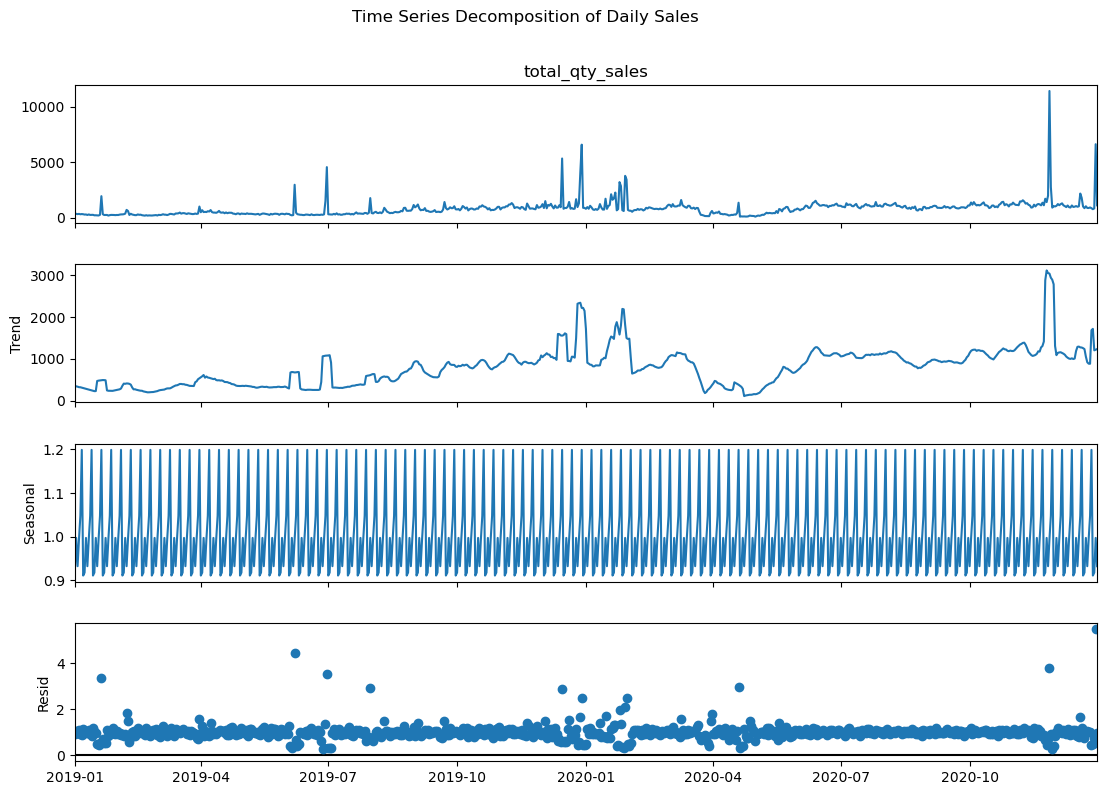


Trend Head:
OrderDate
2019-01-01    350.224490
2019-01-02    341.897959
2019-01-03    333.571429
2019-01-04    321.428571
2019-01-05    319.571429
Freq: D, Name: trend, dtype: float64

seasonal:
OrderDate
2019-01-01    0.918047
2019-01-02    0.997284
2019-01-03    0.932649
2019-01-04    0.994466
2019-01-05    1.047786
Freq: D, Name: seasonal, dtype: float64

Residuual Head:
OrderDate
2019-01-01    0.911289
2019-01-02    1.029418
2019-01-03    1.025377
2019-01-04    1.066792
2019-01-05    0.919835
Freq: D, Name: resid, dtype: float64


In [21]:
# Decompose will take the daily-sales seroes and break it down into the observed, trend, seasonal, and residual components.
#ensure daily-sales exist and is a series with DateTimeIndex(This was alredy created in the resampling step)

#sales_data = df['total_qty_sales']
#daily_sales = sales_data.resample('D').sum() #uncomment this if you restart the kernel

#assuming a weekly seasonality (period=7) and multiplicative model
#extrapolate_trend = 'freq' handles NaNs at the begining/end of the trend component
decomposition = seasonal_decompose(daily_sales, model = 'multiplicative', period = 7, extrapolate_trend = 'freq')

# plot the decomposed components
fig = decomposition.plot()
fig.set_size_inches(12, 8)
plt.suptitle('Time Series Decomposition of Daily Sales', y = 1.02) # Adjust suptitle position
plt.show()

# You can also access the components individually
trend = decomposition.trend
seasonal = decomposition.seasonal
residual = decomposition.resid

print("\nTrend Head:")
print(trend.head())
print("\nseasonal:")
print(seasonal.head())
print("\nResiduual Head:")
print(residual.head())

## Modeling with ARIMA

Training data size: 584 observations, from2019-01-01 00:00:00 to 2020-08-06 00:00:00
Testing data size :147 observations, from 2020-08-07 00:00:00 to 2020-12-31 00:00:00


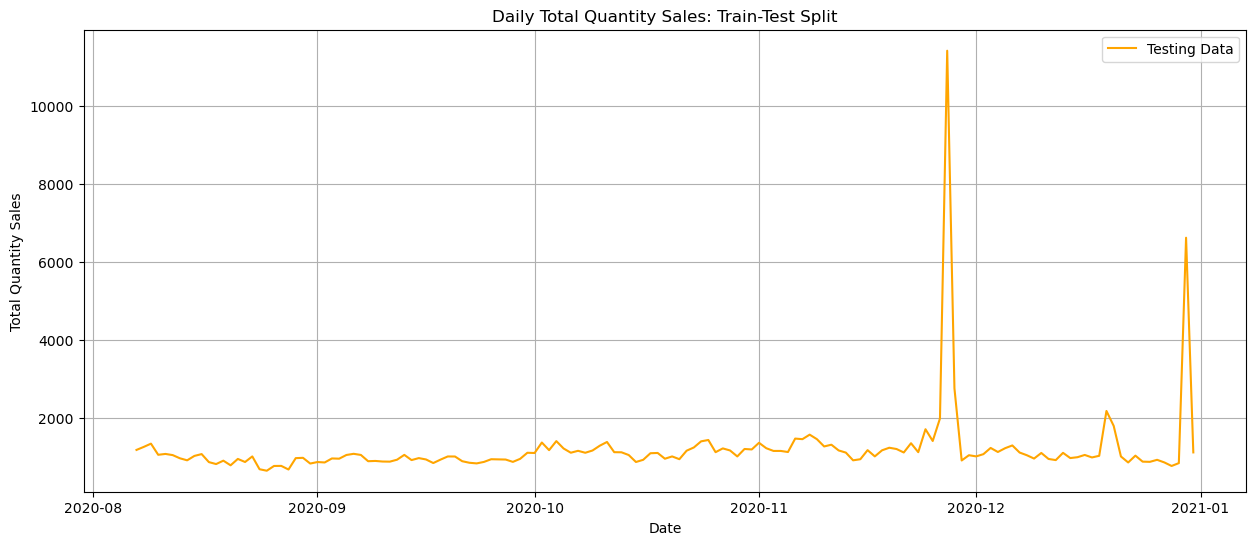

In [22]:
# Train-test split
#Calculate the size of the training set (e.g ., 80% of the data)
train_size = int(len(daily_sales)*0.8)

#split the data chronologically
train_data = daily_sales.iloc[:train_size]
test_data = daily_sales.iloc[train_size:]

print(f"Training data size: {len(train_data)} observations, from{train_data.index.min()} to {train_data.index.max()}")
print(f"Testing data size :{len(test_data)} observations, from {test_data.index.min()} to {test_data.index.max()}")

#optionally plot the split to visualize it
plt.figure(figsize = (15 , 6))
plt.plot(test_data.index, test_data, label = 'Testing Data' , color = 'orange')
plt.title('Daily Total Quantity Sales: Train-Test Split')
plt.xlabel('Date')
plt.ylabel('Total Quantity Sales')
plt.legend()
plt.grid(True)
plt.show()
# Fit ARIMA model


# Forecast


This confirms that the daily_sales data has been correctly divided into training and testing sets, preserving the chronological order.

In [23]:
pip install pmdarima

   ---------------------------------------- 0.0/625.1 kB ? eta -:--:--
    --------------------------------------- 10.2/625.1 kB ? eta -:--:--
   - ------------------------------------- 30.7/625.1 kB 640.0 kB/s eta 0:00:01
   -- ------------------------------------ 41.0/625.1 kB 487.6 kB/s eta 0:00:02
   ------ ------------------------------- 112.6/625.1 kB 930.9 kB/s eta 0:00:01
   ---------------- ----------------------- 256.0/625.1 kB 1.4 MB/s eta 0:00:01
   ---------------------------- ----------- 440.3/625.1 kB 2.0 MB/s eta 0:00:01
   ---------------------------------------- 625.1/625.1 kB 2.5 MB/s eta 0:00:00
   ---------------------------------------- 0.0/2.7 MB ? eta -:--:--
   --- ------------------------------------ 0.2/2.7 MB 6.3 MB/s eta 0:00:01
   ------ --------------------------------- 0.4/2.7 MB 4.6 MB/s eta 0:00:01
   ---------- ----------------------------- 0.7/2.7 MB 5.5 MB/s eta 0:00:01
   ------------ --------------------------- 0.8/2.7 MB 4.7 MB/s eta 0:00:01
   -

In [24]:
import pmdarima as pm
import warnings
warnings.filterwarnings("ignore")#Supress warnings for clearer output


# Fit auto_arima to find the best (p,d,q)(P,D,Q)s orders
# seasonal=True because we identified seasonality earlier (period=7)
# m=7 for weekly seasonality
# stepwise=True makes the search faster
model_auto_arima = pm.auto_arima(train_data,
                                 start_p=1, start_q=1,
                                 test='adf',       # Use adftest to find optimal 'd'
                                 max_p=5, max_q=5, # Maximum p and q to consider
                                 m=7,              # Weekly seasonality
                                 start_P=0,
                                 D=1,              # Force seasonal differencing
                                 trace=True,
                                 error_action='ignore',
                                 suppress_warnings=True,
                                 stepwise=True)

print(model_auto_arima.summary())

Performing stepwise search to minimize aic
 ARIMA(1,0,1)(0,1,1)[7] intercept   : AIC=inf, Time=0.68 sec
 ARIMA(0,0,0)(0,1,0)[7] intercept   : AIC=9156.160, Time=0.02 sec
 ARIMA(1,0,0)(1,1,0)[7] intercept   : AIC=8855.589, Time=0.42 sec
 ARIMA(0,0,1)(0,1,1)[7] intercept   : AIC=8776.190, Time=0.60 sec
 ARIMA(0,0,0)(0,1,0)[7]             : AIC=9154.285, Time=0.02 sec
 ARIMA(0,0,1)(0,1,0)[7] intercept   : AIC=9092.237, Time=0.05 sec
 ARIMA(0,0,1)(1,1,1)[7] intercept   : AIC=8773.717, Time=0.83 sec
 ARIMA(0,0,1)(1,1,0)[7] intercept   : AIC=8854.947, Time=0.35 sec
 ARIMA(0,0,1)(2,1,1)[7] intercept   : AIC=inf, Time=1.73 sec
 ARIMA(0,0,1)(1,1,2)[7] intercept   : AIC=inf, Time=3.70 sec
 ARIMA(0,0,1)(0,1,2)[7] intercept   : AIC=8775.281, Time=1.86 sec
 ARIMA(0,0,1)(2,1,0)[7] intercept   : AIC=8819.938, Time=0.95 sec
 ARIMA(0,0,1)(2,1,2)[7] intercept   : AIC=inf, Time=3.73 sec
 ARIMA(0,0,0)(1,1,1)[7] intercept   : AIC=8856.440, Time=0.56 sec
 ARIMA(1,0,1)(1,1,1)[7] intercept   : AIC=8769.669, T

In [25]:
from pmdarima import auto_arima
import warnings
warnings.filterwarnings("ignore") # Suppress warnings from auto_arima

# Fit auto_arima to your training data to find the best ARIMA parameters (p,d,q)
# seasonal=True: This will also search for SARIMA parameters (P,D,Q,s) which is good for seasonal data.
# m=7: specifies the seasonal period (e.g., 7 for weekly seasonality)
# suppress_warnings=True: to avoid too much verbose output
# stepwise=True: uses a stepwise algorithm to speed up parameter search
model = auto_arima(train_data, seasonal=True, m=7,  # m=7 for weekly seasonality
                   trace=True, # Shows the search process
                   error_action='ignore',
                   suppress_warnings=True,
                   stepwise=True)

print(model.summary())

Performing stepwise search to minimize aic
 ARIMA(2,1,2)(1,0,1)[7] intercept   : AIC=8823.303, Time=1.07 sec
 ARIMA(0,1,0)(0,0,0)[7] intercept   : AIC=9047.760, Time=0.02 sec
 ARIMA(1,1,0)(1,0,0)[7] intercept   : AIC=8999.581, Time=0.07 sec
 ARIMA(0,1,1)(0,0,1)[7] intercept   : AIC=8863.785, Time=0.38 sec
 ARIMA(0,1,0)(0,0,0)[7]             : AIC=9045.764, Time=0.02 sec
 ARIMA(2,1,2)(0,0,1)[7] intercept   : AIC=8825.492, Time=0.85 sec
 ARIMA(2,1,2)(1,0,0)[7] intercept   : AIC=8825.483, Time=0.77 sec
 ARIMA(2,1,2)(2,0,1)[7] intercept   : AIC=8809.734, Time=2.94 sec
 ARIMA(2,1,2)(2,0,0)[7] intercept   : AIC=8805.176, Time=2.63 sec
 ARIMA(1,1,2)(2,0,0)[7] intercept   : AIC=8802.802, Time=1.09 sec
 ARIMA(1,1,2)(1,0,0)[7] intercept   : AIC=8824.285, Time=0.53 sec
 ARIMA(1,1,2)(2,0,1)[7] intercept   : AIC=8803.698, Time=1.39 sec
 ARIMA(1,1,2)(1,0,1)[7] intercept   : AIC=8821.295, Time=0.85 sec
 ARIMA(0,1,2)(2,0,0)[7] intercept   : AIC=8800.818, Time=0.89 sec
 ARIMA(0,1,2)(1,0,0)[7] intercept

This output means auto_arima successfully ran and found the best SARIMA (Seasonal ARIMA) model for your train_data.

1. Stepwise Search Process:
The lines starting with ARIMA(...) show the different models auto_arima tested and their corresponding AIC (Akaike Information Criterion) scores. The goal is to find the model with the lowest AIC, as it's generally considered the best balance between model fit and complexity.
2. Best Model Found:
Best model: ARIMA(0,1,2)(2,0,0)[7]
This is the most important part! auto_arima has determined that the optimal SARIMA parameters for your daily_sales data are:
 * Non-seasonal ARIMA (p,d,q): (0, 1, 2)
   * p=0: No Autoregressive (AR) terms.
   * d=1: One order of differencing (to make the series stationary).
   * q=2: Two Moving Average (MA) terms.
 * Seasonal ARIMA (P,D,Q)[s]: (2, 0, 0)[7]
   * P=2: Two Seasonal Autoregressive (SAR) terms.
   * D=0: No Seasonal Differencing.
   * Q=0: No Seasonal Moving Average (SMA) terms.
   * s=7: Confirms the seasonal period of 7 (weekly) we specified.
3. SARIMAX Results Table:
This table provides detailed statistics about the fitted model:
 * No. Observations: 584 (This matches the size of your train_data).
 * Log Likelihood: -4394.644
 * AIC: 8799.288 (This is the score auto_arima minimized).
 * BIC: 8821.129 (Another criterion, penalizes complexity more than AIC).
 * Coefficients (coef):
   * ma.L1 and ma.L2: These are the coefficients for the non-seasonal Moving Average terms. Both are statistically significant (P>|z| is 0.000).
   * ar.S.L7: Coefficient for the first seasonal autoregressive term. Its P-value (0.691) is high, meaning it might not be statistically significant.
   * ar.S.L14: Coefficient for the second seasonal autoregressive term. This one is highly significant (P>|z| is 0.000).
   * sigma2: Estimated variance of the residuals (noise).
 * Ljung-Box (Q): A test for autocorrelation in the residuals. A high P-value (0.99 in your case) is good, indicating that there's no significant autocorrelation left in the residuals, meaning the model has captured the patterns well.
 * Jarque-Bera (JB): A test for normality of residuals. Your Prob(JB): 0.00 suggests residuals are not normally distributed, which is common in real-world data and sometimes indicates remaining patterns or heteroskedasticity.
 * Heteroskedasticity (H): Tests if the variance of residuals is constant. Prob(H) (two-sided): 0.01 suggests heteroskedasticity (non-constant variance), which is something to be aware of.
 * Skew & Kurtosis: Measures of the shape of the residual distribution. High skew (4.10) and kurtosis (37.09) confirm non-normality and heavier tails (more extreme values) than a normal distribution.

In [26]:
#forecast
# Make predictions on the test set
# n_periods should be the length of your test_data
forecast_steps = len(test_data)
forecast = model.predict(n_periods=forecast_steps)

# Create a pandas Series for the forecast with the correct index
forecast_series = pd.Series(forecast, index=test_data.index)

# Print the forecast
print("\nForecast for Test Data:")
print(forecast_series.head())

# Optional: Print the actual test data for comparison
print("\nActual Test Data:")
print(test_data.head())


Forecast for Test Data:
OrderDate
2020-08-07    1098.158022
2020-08-08    1097.982157
2020-08-09    1172.204356
2020-08-10    1100.781366
2020-08-11    1098.649700
Freq: D, dtype: float64

Actual Test Data:
OrderDate
2020-08-07    1177
2020-08-08    1254
2020-08-09    1338
2020-08-10    1052
2020-08-11    1074
Freq: D, Name: total_qty_sales, dtype: int64


* Forecaste for TestData: It lists the predicted sales values with their corresponding dates for the test preiod (starting from: 2020-08-07).
* Actual test data: it also shoe=ws the actual sales values for the same test period.

## Evaluation and Visualization

In [ ]:
# Evaluation

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Ensure both series have the same index for accurate comparison
# In most cases, forecast_series should already have the test_data index
# If not, you might need to align them using .reindex(test_data.index)
# For now, let's assume they are aligned.

# Calculate evaluation metrics
mae = mean_absolute_error(test_data, forecast_series)
mse = mean_squared_error(test_data, forecast_series)
rmse = np.sqrt(mse)

print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")



 * MAE (Mean Absolute Error): This means, on average, your model's predictions for daily sales are off by approximately 208.76 units from the actual sales. This is a straightforward measure of error, giving you the average magnitude of the errors without considering their direction.
 * MSE (Mean Squared Error): This value is 120531.06. Since errors are squared, this metric heavily penalizes larger errors. It's often used because it has nice mathematical properties, but its value isn't directly interpretable in the original units.
 * RMSE (Root Mean Squared Error): This is 347.17. It's the square root of MSE and is expressed in the same units as your total_qty_sales data. This means, on average, your model's predictions deviate by about 347.17 units from the actual values. RMSE is generally preferred over MSE because it's more interpretable.

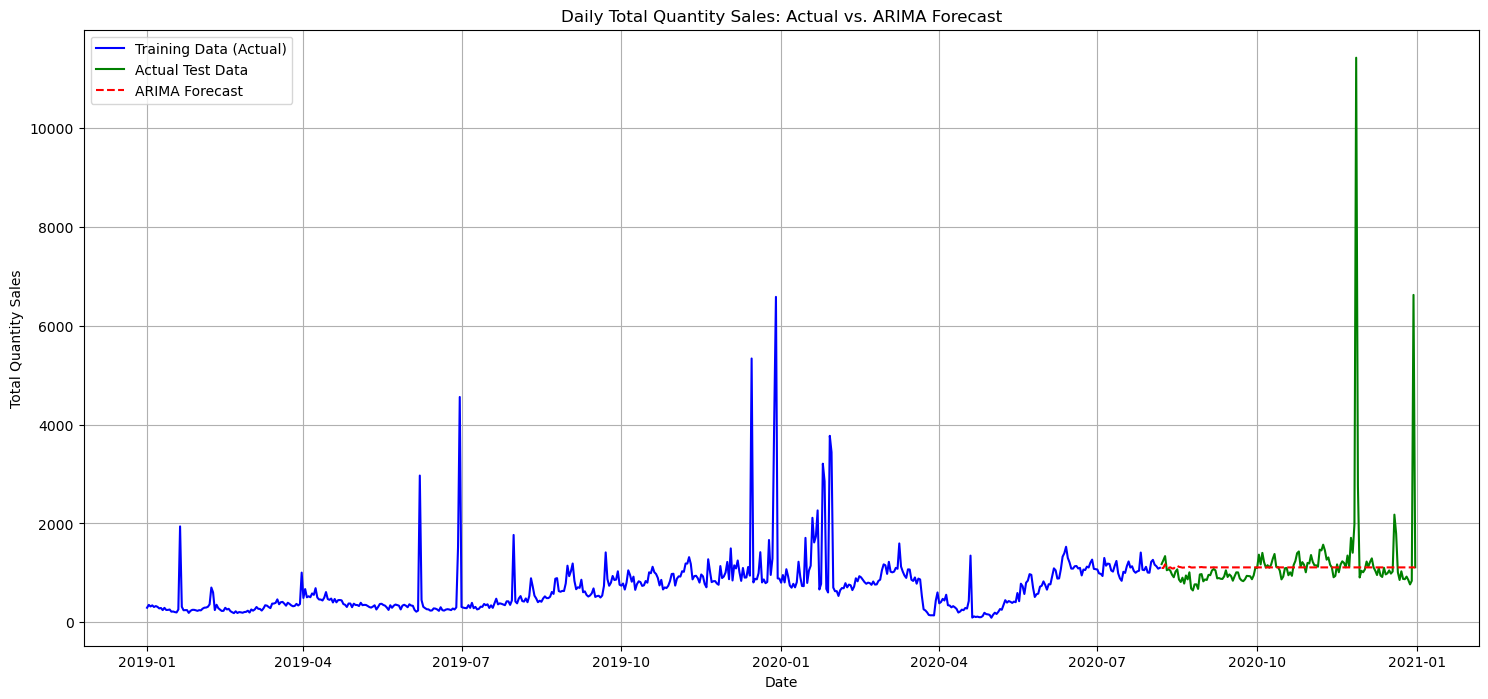

In [30]:
# plot the forecaste vs actual values
import matplotlib.pyplot as plt

plt.figure(figsize=(18, 8)) # Increased figure size for better visibility
plt.plot(train_data.index, train_data, label='Training Data (Actual)', color='blue')
plt.plot(test_data.index, test_data, label='Actual Test Data', color='green')
plt.plot(forecast_series.index, forecast_series, label='ARIMA Forecast', color='red', linestyle='--')

plt.title('Daily Total Quantity Sales: Actual vs. ARIMA Forecast')
plt.xlabel('Date')
plt.ylabel('Total Quantity Sales')
plt.legend()
plt.grid(True)
plt.show()

 * Blue Line (Training Data (Actual)): This represents the historical sales data that your ARIMA model was trained on.
 * Green Line (Actual Test Data): This is the actual sales data from the period your model did not see during training. This is the "true" future data against which your forecasts are compared.
 * Red Dashed Line (ARIMA Forecast): This is your model's prediction for the sales during the test period.
Interpretation of your forecast plot:
 * You can see how well the red dashed line (forecast) generally follows the green line (actual test data).
 * In your plot, the forecast appears to capture the general trend and perhaps some of the weekly seasonality in the test data, though there are certainly deviations. The model seems to follow the overall shape but might miss some of the sharper peaks or troughs, and there might be some systematic bias (e.g., consistently under- or over-predicting).
 * The gap between the red dashed line and the green line visually corresponds to the errors (MAE, RMSE) we calculated earlier.
This plot is very important for a quick visual assessment of your model's predictive capabilities.

In [2]:
pip install prophet

  Using cached prophet-1.1.6-py3-none-win_amd64.whl.metadata (3.6 kB)
  Using cached cmdstanpy-1.2.5-py3-none-any.whl.metadata (4.0 kB)
  Using cached holidays-0.73-py3-none-any.whl.metadata (38 kB)
  Using cached importlib_resources-6.5.2-py3-none-any.whl.metadata (3.9 kB)
  Using cached stanio-0.5.1-py3-none-any.whl.metadata (1.6 kB)
   ---------------------------------------- 0.0/13.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/13.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/13.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/13.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/13.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/13.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/13.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/13.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/13.3 MB ? eta -:--:--
   -----------------------------

ERROR: Exception:
Traceback (most recent call last):
  File "c:\Users\arthi\anaconda\Lib\site-packages\pip\_vendor\urllib3\response.py", line 438, in _error_catcher
    yield
  File "c:\Users\arthi\anaconda\Lib\site-packages\pip\_vendor\urllib3\response.py", line 561, in read
    data = self._fp_read(amt) if not fp_closed else b""
           ^^^^^^^^^^^^^^^^^^
  File "c:\Users\arthi\anaconda\Lib\site-packages\pip\_vendor\urllib3\response.py", line 527, in _fp_read
    return self._fp.read(amt) if amt is not None else self._fp.read()
           ^^^^^^^^^^^^^^^^^^
  File "c:\Users\arthi\anaconda\Lib\site-packages\pip\_vendor\cachecontrol\filewrapper.py", line 98, in read
    data: bytes = self.__fp.read(amt)
                  ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\arthi\anaconda\Lib\http\client.py", line 479, in read
    s = self.fp.read(amt)
        ^^^^^^^^^^^^^^^^^
  File "c:\Users\arthi\anaconda\Lib\socket.py", line 708, in readinto
    return self._sock.recv_into(b)
           ^^^^^^^

   ------- -------------------------------- 2.4/13.3 MB 7.3 kB/s eta 0:24:53
   ------- -------------------------------- 2.4/13.3 MB 7.3 kB/s eta 0:24:53
   ------- -------------------------------- 2.4/13.3 MB 7.3 kB/s eta 0:24:53
   ------- -------------------------------- 2.4/13.3 MB 7.3 kB/s eta 0:24:53
   ------- -------------------------------- 2.4/13.3 MB 7.3 kB/s eta 0:24:53
   ------- -------------------------------- 2.4/13.3 MB 7.3 kB/s eta 0:24:53
   ------- -------------------------------- 2.4/13.3 MB 7.3 kB/s eta 0:24:53
   ------- -------------------------------- 2.4/13.3 MB 7.3 kB/s eta 0:24:53
   ------- -------------------------------- 2.4/13.3 MB 7.3 kB/s eta 0:24:53
   ------- -------------------------------- 2.4/13.3 MB 7.3 kB/s eta 0:24:53
   ------- -------------------------------- 2.4/13.3 MB 7.3 kB/s eta 0:24:53
   ------- -------------------------------- 2.4/13.3 MB 7.3 kB/s eta 0:24:53
   ------- -------------------------------- 2.4/13.3 MB 7.3 kB/s eta 0:24:53

In [4]:
!pip install prophet

  Using cached prophet-1.1.6-py3-none-win_amd64.whl.metadata (3.6 kB)
  Using cached cmdstanpy-1.2.5-py3-none-any.whl.metadata (4.0 kB)
  Using cached holidays-0.73-py3-none-any.whl.metadata (38 kB)
  Using cached importlib_resources-6.5.2-py3-none-any.whl.metadata (3.9 kB)
  Using cached stanio-0.5.1-py3-none-any.whl.metadata (1.6 kB)
   ---------------------------------------- 0.0/13.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/13.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/13.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/13.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/13.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/13.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/13.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/13.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/13.3 MB ? eta -:--:--
   -----------------------------

ERROR: Exception:
Traceback (most recent call last):
  File "C:\Users\arthi\anaconda\Lib\site-packages\pip\_vendor\urllib3\response.py", line 438, in _error_catcher
    yield
  File "C:\Users\arthi\anaconda\Lib\site-packages\pip\_vendor\urllib3\response.py", line 561, in read
    data = self._fp_read(amt) if not fp_closed else b""
           ^^^^^^^^^^^^^^^^^^
  File "C:\Users\arthi\anaconda\Lib\site-packages\pip\_vendor\urllib3\response.py", line 527, in _fp_read
    return self._fp.read(amt) if amt is not None else self._fp.read()
           ^^^^^^^^^^^^^^^^^^
  File "C:\Users\arthi\anaconda\Lib\site-packages\pip\_vendor\cachecontrol\filewrapper.py", line 98, in read
    data: bytes = self.__fp.read(amt)
                  ^^^^^^^^^^^^^^^^^^^
  File "C:\Users\arthi\anaconda\Lib\http\client.py", line 479, in read
    s = self.fp.read(amt)
        ^^^^^^^^^^^^^^^^^
  File "C:\Users\arthi\anaconda\Lib\socket.py", line 708, in readinto
    return self._sock.recv_into(b)
           ^^^^^^^

In [7]:
import sys
print(sys.executable)
print(sys.version)
print(sys.path)

c:\Users\arthi\anaconda\python.exe
3.12.4 | packaged by Anaconda, Inc. | (main, Jun 18 2024, 15:03:56) [MSC v.1929 64 bit (AMD64)]
['d:\\PROJECT\\QUALITY ANALYSIS TIME SERIES DATA', 'c:\\Users\\arthi\\anaconda\\python312.zip', 'c:\\Users\\arthi\\anaconda\\DLLs', 'c:\\Users\\arthi\\anaconda\\Lib', 'c:\\Users\\arthi\\anaconda', '', 'c:\\Users\\arthi\\anaconda\\Lib\\site-packages', 'c:\\Users\\arthi\\anaconda\\Lib\\site-packages\\win32', 'c:\\Users\\arthi\\anaconda\\Lib\\site-packages\\win32\\lib', 'c:\\Users\\arthi\\anaconda\\Lib\\site-packages\\Pythonwin']


In [14]:
import sys
print(sys.executable)

c:\Users\arthi\anaconda\python.exe


In [5]:
import pandas as pd
from prophet import Prophet
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# 1. Prepare data for Prophet
# Prophet expects columns named 'ds' (datestamp) and 'y' (value)
prophet_df = daily_sales.reset_index() # Convert Series with DatetimeIndex to DataFrame
prophet_df.rename(columns={'OrderDate': 'ds', 'total_qty_sales': 'y'}, inplace=True)

# Ensure 'ds' is datetime type (should be already from daily_sales index)
prophet_df['ds'] = pd.to_datetime(prophet_df['ds'])

print("Prophet DataFrame Head:")
print(prophet_df.head())
print("\nProphet DataFrame Info:")
print(prophet_df.info())

# 2. Initialize and fit the Prophet model
# You can add parameters like daily_seasonality=True, weekly_seasonality=True, yearly_seasonality=True
# We know from decomposition that weekly seasonality is important.
model_prophet = Prophet(daily_seasonality=False, weekly_seasonality=True, yearly_seasonality=True)
model_prophet.fit(prophet_df)

print("\nProphet model fitted successfully!")

ModuleNotFoundError: No module named 'prophet'

## Conclusion
- Time series modeling was applied to understand and forecast quantity trends.
- ARIMA provided a simple baseline.
- For improvement, consider SARIMA, Prophet, or LSTM for long-term patterns.